# Proxy informativeness

How well can each bridge estimate the causal function when a proxy becomes a **worse measurement of the latent confounder**? We degrade one proxy at a time and re-run the whole pipeline.

### What `s` is

For a proxy $P$ we replace it by

$$\tilde P_{ij} \;=\; P_{ij} \;+\; s\,\hat\sigma_j\,\varepsilon_{ij}, \qquad \varepsilon_{ij}\sim\mathcal N(0,1),$$

where $\hat\sigma_j$ is the empirical standard deviation of that proxy's own column $j$ (for the 4096-pixel image proxy, its **global** standard deviation, since the background pixels are constant). So `s` is measured in units of the proxy's own spread: `s = 1` adds measurement noise as large as the signal itself (a signal-to-noise ratio of 1), `s = 2` quadruples the noise variance, and `s = 0` is the untouched benchmark. Everything else -- the treatment, the outcome, the latent confounder, the train/estimation split, the network initialisation -- is held fixed.

### What we sweep

**One proxy at a time**, never both: the *outcome proxy* $W$ (the outcome bridge's argument $h(a,W)$, and the treatment bridge's conditioning variable) and the *treatment proxy* $Z$ (the treatment bridge's argument $\varphi(a,Z)$, and the outcome bridge's conditioning variable). Demand: $s \in \{0, 0.25, 0.5, 1, 2, 4\}$; dSprite V3: $s \in \{0, 1, 4\}$ (its runs are minutes, not seconds). The `s = 0` cell is shared by both arms.

n = 4000 throughout; causal MSE as mean ± SE over 10 data seeds, 3 repeats averaged within each seed. The noise is drawn from a random stream separate from the one the data generator, the fold split, the initialisation and the estimation consume, so every level is a within-seed controlled ablation of `s = 0`.

`R² (U | proxy)` reports the measured informativeness that results: the $R^2$ of a quadratic regression of the latent confounder $U$ on the noised proxy (on its leading 20 principal directions, for the image proxy).

In [1]:
import sys, glob
sys.path.insert(0, "../../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from python_utils.visualization_utils import COLOR_PALETTE

ALG   = ["OutcomeNet", "TreatmentNet", "DRPCLNET-V1"]
NICE  = {"OutcomeNet": "OutcomeNet", "TreatmentNet": "TreatmentNet", "DRPCLNET-V1": "DR-PCL-Net"}
STYLE = {"OutcomeNet": ("#1f77b4", "--", "s"), "TreatmentNet": ("#ff7f0e", "--", "s"),
         "DR-PCL-Net": (COLOR_PALETTE.get("DRPCLNET (V1)", "#d62728"), "-", "o")}

def load(folder):
    """One row per (estimator, arm, noise level, seed, repeat). The s=0 cell is shared by both arms."""
    d = pd.concat([x for x in (pd.read_csv(f) for f in glob.glob("../Results/%s/*.csv" % folder)) if len(x)])
    d = d[d.Algorithm.isin(ALG)].copy()
    d["arm"]   = np.where(d.w_noise > 0, "W", "Z")
    d["level"] = np.where(d.w_noise > 0, d.w_noise, d.z_noise)
    return pd.concat([d, d[d.level == 0].assign(arm="W")])      # replicate the shared baseline into arm W

def per_seed(d):
    """Repeats averaged within a data seed -- the pairing unit, as everywhere else in the paper."""
    return d.groupby(["arm", "Algorithm", "level", "Data_Seed"]).Causal_MSE.mean()

def informativeness(dgp, level, arm, n=20000, seed=100):
    """Measured informativeness of the (noised) proxy: R^2 of the latent confounder U from it.
    Quadratic in the proxy, since the demand proxies are non-linear in U. Uses the SAME noise
    convention as the simulations (dedicated RandomState keyed on the data seed)."""
    from simulation_utils.data_generating_processes import (generate_demand_experiment_data,
                                                            dSprite_ProxyVariable_DatasetV3)
    if dgp == "demand":
        U, W, Z, A, Y, _, _ = generate_demand_experiment_data(size=n, epsilon_std=1.0, seed=seed)
    else:
        g = dSprite_ProxyVariable_DatasetV3()
        out = g.generate_dsprite_pv("../../data/dsprite", n_sample=n, rand_seed=seed, return_latents=True)
        A, Y, Z, W = out[:4]; U = out[6]["U"]
    rng = np.random.RandomState(int(seed) + 100003)
    W, Z = np.asarray(W, float).copy(), np.asarray(Z, float).copy()
    if arm == "W" and level > 0:
        sd = W.std() if W.shape[1] > 100 else W.std(0, keepdims=True)
        W += level * sd * rng.randn(*W.shape)
    if arm == "Z" and level > 0:
        Z += level * Z.std(0, keepdims=True) * rng.randn(*Z.shape)
    P = np.asarray(W if arm == "W" else Z, float)
    if P.shape[1] > 100:                                   # image proxy: use its leading principal directions
        P = P - P.mean(0); P = P @ np.linalg.svd(P[:2000], full_matrices=False)[2][:20].T
    u = np.asarray(U, float).ravel()
    X = np.c_[np.ones(len(u)), P, P ** 2]
    beta, *_ = np.linalg.lstsq(X, u, rcond=None)
    return 1.0 - ((u - X @ beta) ** 2).mean() / u.var()

def table(ps, dgp, nd=1):
    for arm in ("W", "Z"):
        g = ps.loc[arm].groupby(["Algorithm", "level"])
        m, se = g.mean(), g.std() / np.sqrt(g.size())
        t = (m.map(("{:.%df}" % nd).format) + " ± " + se.map(("{:.%df}" % nd).format)).unstack().reindex(ALG)
        t.index = [NICE[a] for a in t.index]
        t.loc["R² (U | proxy)"] = ["%.3f" % informativeness(dgp, c, arm) for c in t.columns]
        t.columns = ["s=%g" % c for c in t.columns]
        print("noise on %s" % ("W (outcome proxy)" if arm == "W" else "Z (treatment proxy)"))
        print(t.to_string(), "\n")

def plot(ps, title, logy=True):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for ax, arm, lab in zip(axes, ("W", "Z"), ("outcome proxy $W$", "treatment proxy $Z$")):
        g = ps.loc[arm].groupby(["Algorithm", "level"])
        m, se = g.mean().unstack(), (g.std() / np.sqrt(g.size())).unstack()
        x = np.arange(len(m.columns))
        for a in ALG:
            c, ls, mk = STYLE[NICE[a]]
            ax.plot(x, m.loc[a], ls, color=c, marker=mk, lw=3.0 if ls == "-" else 2.0,
                    ms=9, label=NICE[a])
            ax.fill_between(x, m.loc[a] - 1.96 * se.loc[a], m.loc[a] + 1.96 * se.loc[a], color=c, alpha=0.15)
        ax.set_xticks(x); ax.set_xticklabels(["%g" % c for c in m.columns], fontsize=13)
        ax.set_xlabel("noise level $s$ on the %s" % lab, fontsize=15)
        if logy: ax.set_yscale("log")
        ax.grid(True, which="both", ls=":", alpha=0.6)
    axes[0].set_ylabel("Causal Mean Squared Error", fontsize=15)
    axes[0].legend(fontsize=12, frameon=True, shadow=True)
    fig.suptitle(title, fontsize=17, fontweight="bold")
    fig.tight_layout(); plt.show()

demand = per_seed(load("Demand_ProxyNoise"))
v3 = per_seed(load("dSprite_V3_ProxyNoise"))

## Demand

The demand benchmark of Xu et al. (2021), unchanged. The latent confounder is the **demand level** $U \sim \mathrm{Unif}(0,10)$, which drives price, views and sales at once:

$$\psi(t) = 2\Big(\tfrac{(t-5)^4}{600} + e^{-4(t-5)^2} + \tfrac{t}{10} - 2\Big)$$
$$Z = (C_1, C_2),\quad C_1 = 2\sin(2\pi U/10) + \epsilon,\quad C_2 = 2\cos(2\pi U/10) + \epsilon \qquad \text{(cost shifters)}$$
$$A = 35 + (C_1+3)\,\psi(U) + C_2 + \epsilon \qquad \text{(price)}$$
$$W = 7\,\psi(U) + 45 + \epsilon \qquad \text{(views)}$$
$$Y = \min\{e^{(W-A)/10}, 5\}\cdot A - 5\,\psi(U) + \epsilon \qquad \text{(sales)}$$

with $\epsilon \sim \mathcal N(0,1)$ independently everywhere. The target is $E[Y \mid do(A=a)]$ on 10 prices in $[10,30]$. Both proxies are continuous and low-dimensional, so the noise scale is directly interpretable.

In [2]:
table(demand, "demand", nd=1)

noise on W (outcome proxy)
                         s=0       s=0.25         s=0.5          s=1          s=2          s=4
OutcomeNet        27.5 ± 2.5   27.4 ± 2.4    30.9 ± 2.5   55.5 ± 4.0  118.9 ± 7.1  178.0 ± 6.0
TreatmentNet    163.4 ± 11.1  175.0 ± 8.6  186.9 ± 10.5  200.9 ± 6.2  203.6 ± 3.5  200.2 ± 2.4
DR-PCL-Net        22.3 ± 2.2   22.4 ± 2.1    26.3 ± 2.5   50.3 ± 3.7  113.9 ± 6.3  170.0 ± 5.5
R² (U | proxy)         0.460        0.432         0.369        0.237        0.097        0.028



noise on Z (treatment proxy)
                         s=0        s=0.25         s=0.5           s=1           s=2           s=4
OutcomeNet        27.5 ± 2.5    38.5 ± 5.0    59.5 ± 7.7   101.7 ± 7.8   157.0 ± 7.7   196.3 ± 7.9
TreatmentNet    163.4 ± 11.1  175.9 ± 11.2  162.8 ± 14.9  169.9 ± 14.7  183.3 ± 17.8  194.1 ± 18.4
DR-PCL-Net        22.3 ± 2.2    31.4 ± 4.5    50.2 ± 7.6    91.7 ± 7.7   148.7 ± 7.3   190.5 ± 7.8
R² (U | proxy)         0.402         0.378         0.322         0.201         0.080         0.023



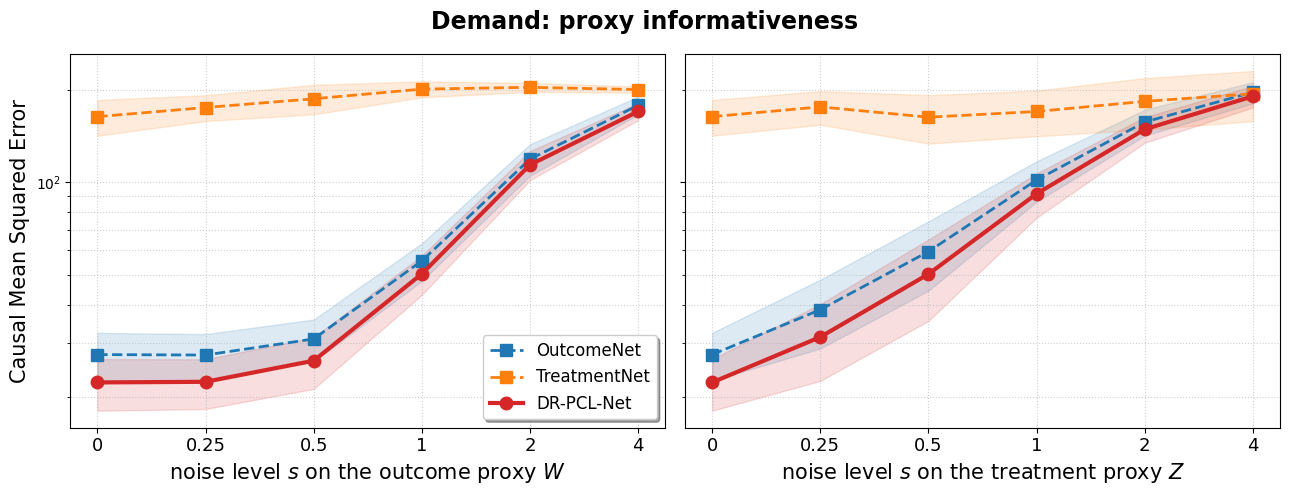

In [3]:
plot(demand, "Demand: proxy informativeness")

## dSprite V3

Image-valued treatment with a latent confounder that is **never rendered into the image**. $U \sim \mathrm{Unif}(0,1)$ shifts the sprite's horizontal position only stochastically, so $U$ is not recoverable from $A$:

$$\mathrm{posX}_A = \mathrm{disc}_{32}\!\big(U + 0.25\,\epsilon\big), \qquad A = \mathrm{image}(\mathrm{scale}, \mathrm{orientation}, \mathrm{posX}_A, \mathrm{posY}_A) + 0.1\,\epsilon \in \mathbb R^{4096}$$
$$Z = \big(U + 0.40\,\epsilon,\; U + \mathrm{Unif}(-0.6, 0.6)\big) \qquad \text{(2-D noisy view of } U\text{)}$$
$$W = \mathrm{image}\big(\mathrm{posY}_W = \mathrm{disc}_{32}(U + 0.30\,\epsilon)\big) + 0.1\,\epsilon \in \mathbb R^{4096}$$
$$Y = \mathrm{struct}(A)\,q(U) + 0.5\,\epsilon, \qquad q(u) \propto e^{3(u-1/2)}, \; E[q(U)] = 1 \;\Rightarrow\; E[Y \mid do(A=a)] = \mathrm{struct}(a)$$

evaluated on the 588-image test grid. Note both proxies are **already noisy measurements of $U$ at `s = 0`** ($R^2 \approx 0.5$), unlike demand, so this benchmark starts much closer to its information floor.

In [4]:
table(v3, "v3", nd=2)

noise on W (outcome proxy)
                         s=0           s=1           s=4
OutcomeNet      12.19 ± 0.15  11.51 ± 0.18  13.79 ± 0.53
TreatmentNet    15.56 ± 0.27  15.67 ± 0.25  15.72 ± 0.24
DR-PCL-Net      11.57 ± 0.16  10.75 ± 0.16  10.68 ± 0.09
R² (U | proxy)         0.489         0.488         0.477



noise on Z (treatment proxy)
                         s=0           s=1           s=4
OutcomeNet      12.19 ± 0.15  13.24 ± 0.19  14.85 ± 0.26
TreatmentNet    15.56 ± 0.27  16.23 ± 0.22  16.35 ± 0.19
DR-PCL-Net      11.57 ± 0.16  13.13 ± 0.16  15.19 ± 0.22
R² (U | proxy)         0.545         0.311         0.040



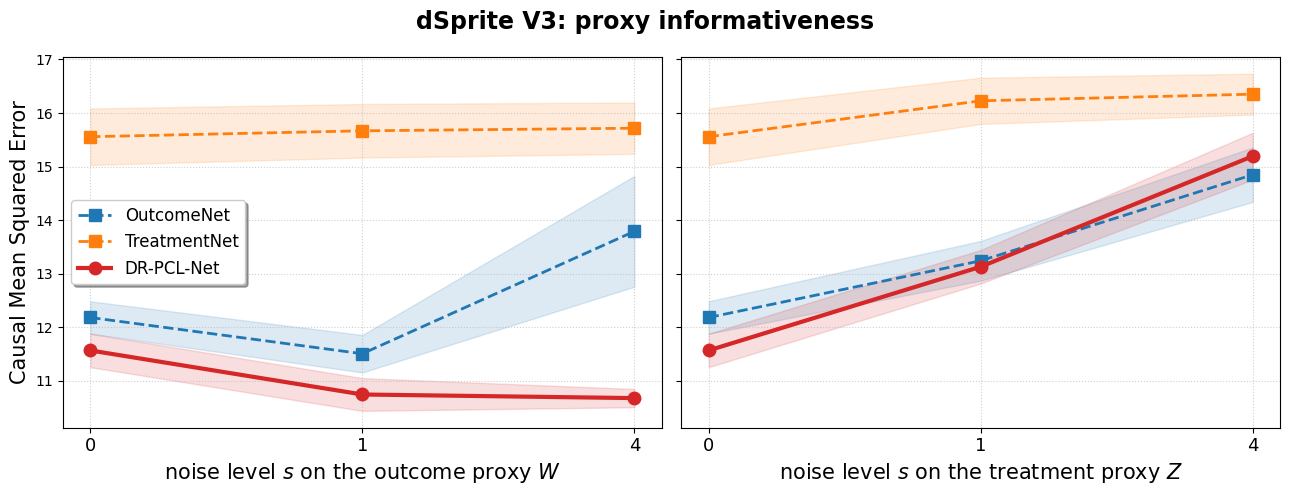

In [5]:
plot(v3, "dSprite V3: proxy informativeness", logy=False)